# Carbonate atoll: wave direction on a sinking volcanic island

A volcanic island (+150 m) sinks at 0.5 mm/yr for 600 kyr: its fringing reef
becomes a barrier reef, then, once the summit drowns (~300 kyr), an atoll
(Darwin's sequence). All runs have the same island and carbonate factories;
they differ by the wave climate (and one by the sea level). The reef builders
need wave energy, so the waves decide where the reef rim grows. The runs are
described in `README.md` and in the header of each `input-*.yml`; run
`python scripts/make_inputs.py` and `./run_all.sh` first. The plotting
functions are in `scripts/atoll.py`.

In [1]:
import sys
sys.path.insert(0, 'scripts')
import matplotlib.pyplot as plt
import atoll as A

RUNS = ['nowaves', 'ring', 'east', 'season', 'refraction', 'erosion', 'sealevel']
SIMS = ['sim_' + r for r in RUNS]

## Darwin's sequence: waves from all directions (`input-ring.yml`)

Every 150 kyr: the fringing reef around the island (black: shoreline; grey:
-25 m, the limit of the reef builders) grows up as the island sinks, the
island shrinks inside a lagoon, and after ~300 kyr only the reef rim and the
lagoon remain.

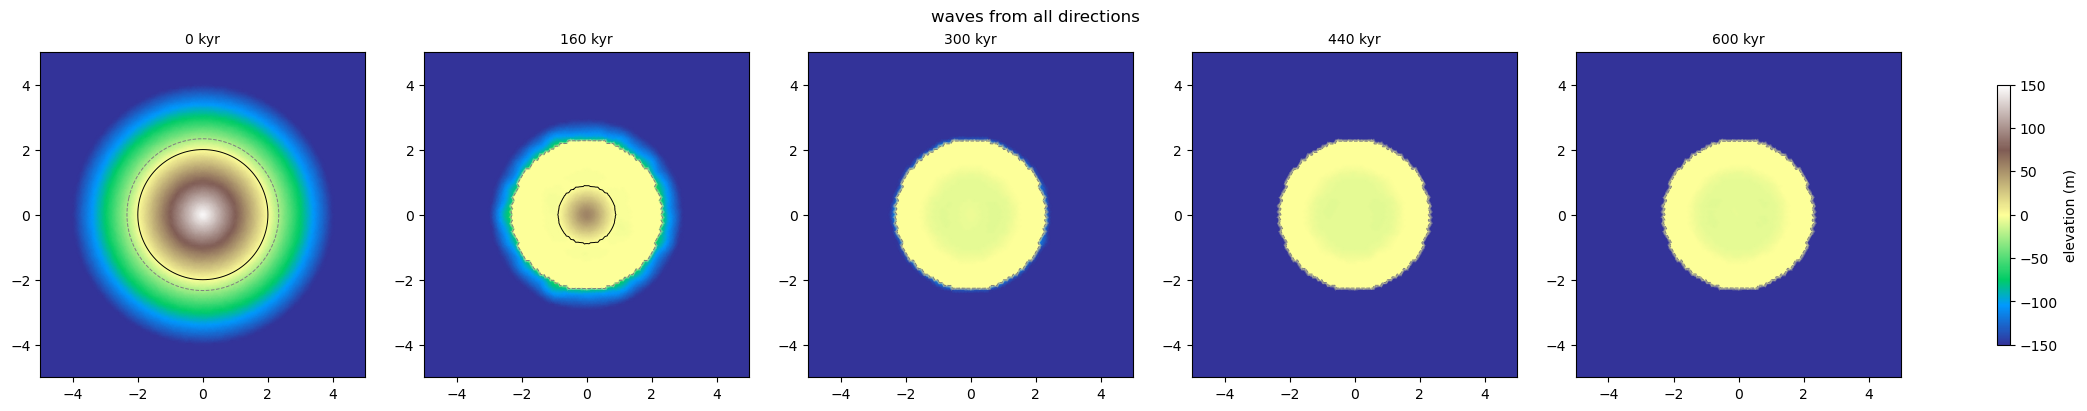

In [2]:
A.evolution('sim_ring', n=5, title='waves from all directions');

## Trade winds from the east (`input-east.yml`)

With one wave direction the reef builders only find energy on the windward
side and on the flanks: the island casts a wave shadow downwind, the leeward
reef grows at 2 % of its potential and drowns as the island sinks. The result
is a windward crescent reef, not a ring.

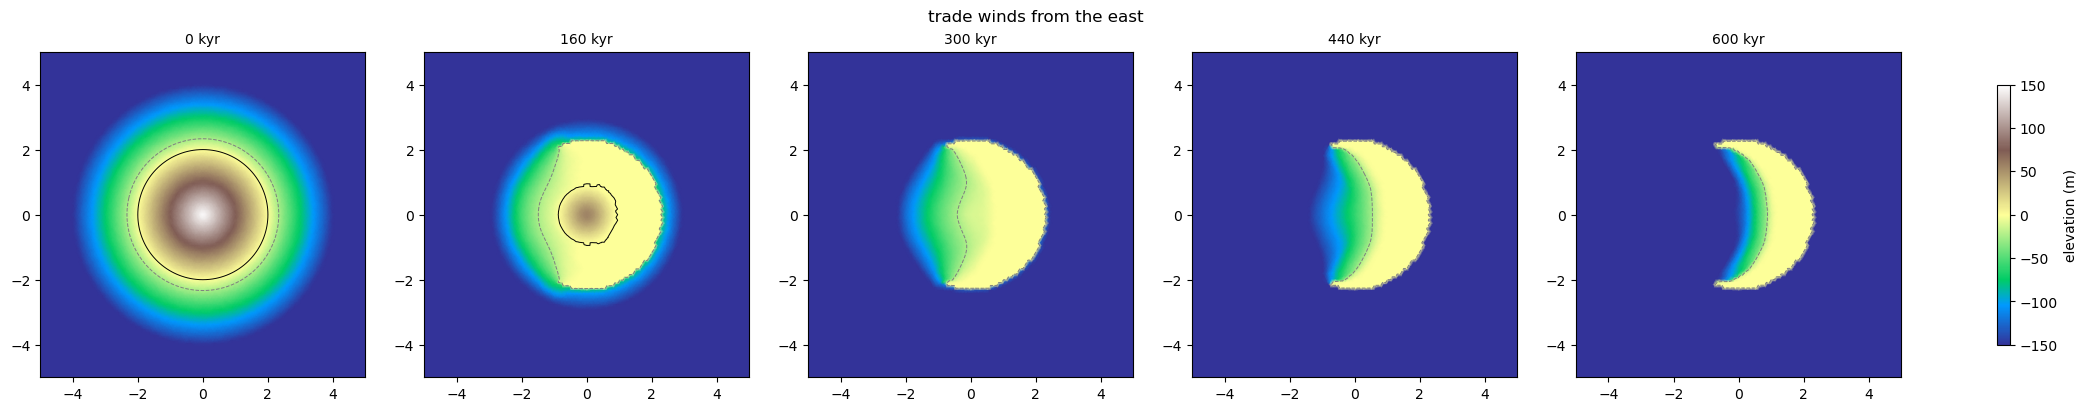

In [3]:
A.evolution('sim_east', n=5, title='trade winds from the east');

## The wave climate decides the shape

The wave energy at the end of each run (cyan: -10 m contour), the reef
framework thickness and the final elevation.

- **no waves**: the reef grows everywhere the light allows and the platform
  fills to sea level (no lagoon);
- **ring** (eight directions): a rim all around and a shallow lagoon (7-8 m;
  the lagoon factory and the sand shed from the rim almost keep up);
- **east**: a windward crescent, the lee drowned (centre at -140 m);
- **season** (east 70 %, south-south-west 30 %): the rim follows both
  directions, a horseshoe open to the north-west;
- **refraction**: hardly different from **east** (6.5 against 6.6 km2 of reef
  flat): refraction turns the waves towards the shore on the flanks, but the
  wave solve has no diffraction, so it cannot carry energy into the shadow
  behind the island;
- **erosion**: the eroded reef, moved as carbonate sand (`rubble`), partly
  fills the lagoon (centre at -98 m instead of -140 m) and the rim builds
  20 % more framework;
- **sealevel**: see below.

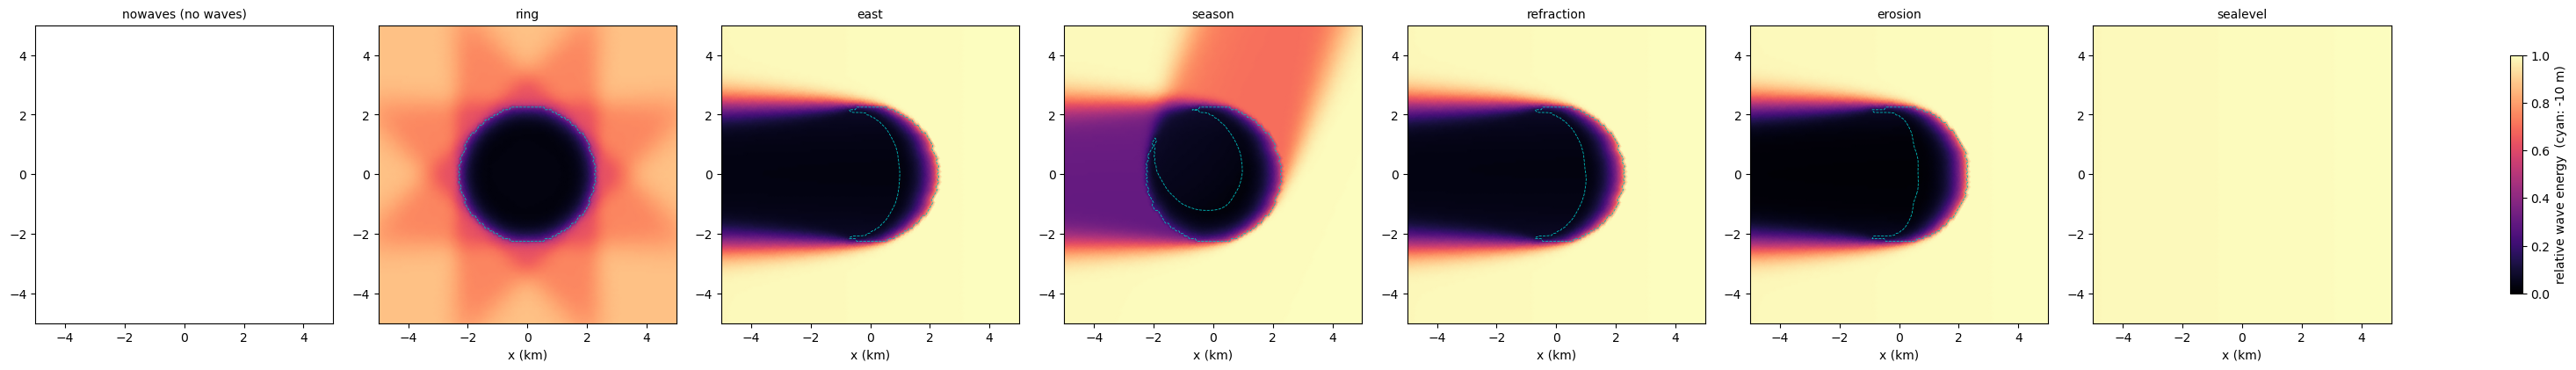

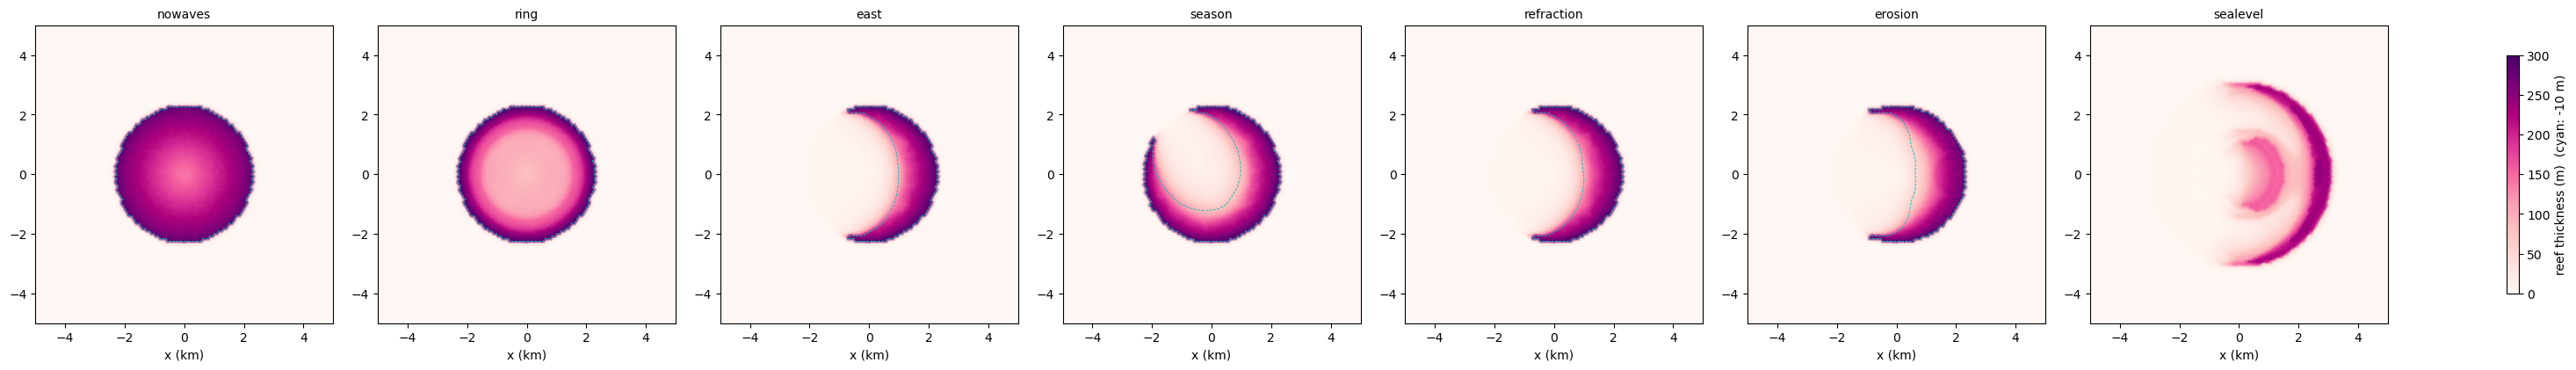

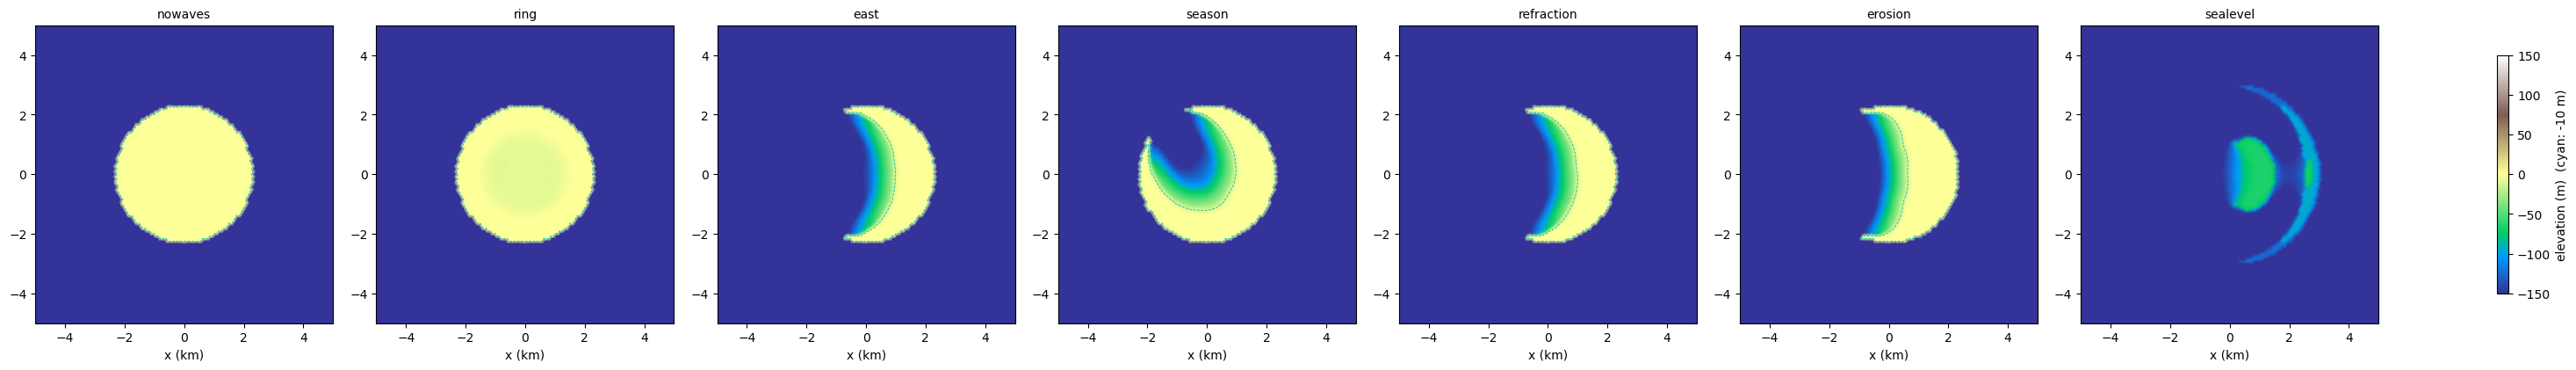

In [4]:
A.compare(SIMS, RUNS, 'waveE')
A.compare(SIMS, RUNS, 'reef')
A.compare(SIMS, RUNS, 'elev');

Sections through the centre of the island, west-east (along the trade winds)
and south-north, coloured by lithology (volcanic sand yellow and mud grey,
carbonate sand light blue, carbonate mud dark blue, reef pink): the
windward rim stacks reef on the sinking volcano, the leeward side carries a
thin reef that drowned.

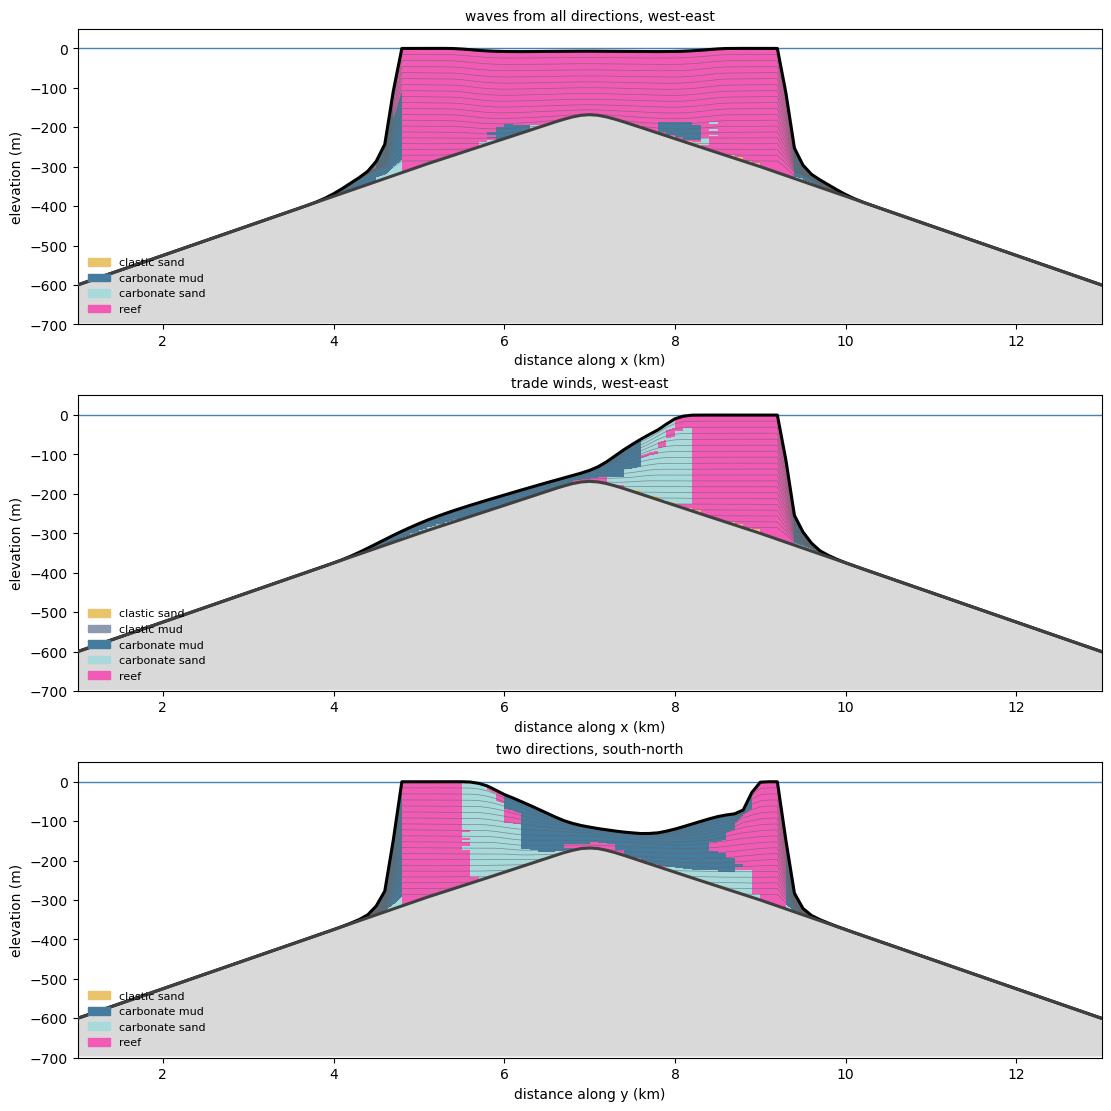

In [5]:
fig, ax = plt.subplots(3, 1, figsize=(11, 11), constrained_layout=True)
A.section('sim_ring', 'x', ax=ax[0], title='waves from all directions, west-east')
A.section('sim_east', 'x', ax=ax[1], title='trade winds, west-east')
A.section('sim_season', 'y', ax=ax[2], title='two directions, south-north');

## Glacial sea level (`input-sealevel.yml`)

The trade-wind run under the Quaternary sea level of Spratt & Lisiecki (2016,
long stack, 0-600 ka, shifted to 0 m at present). The lowstands (down to
-139 m) expose the platform and move the reef down the windward flank,
where it builds a crescent about 3 km from the centre, outside the old
platform. The last
deglacial rise (up to 15 mm/yr in the last 20 kyr) is faster than the reef
can follow: the reef builders stop below 25 m, and once the old platform top
is deeper than that nothing shallow is left to grow on. The atoll drowns
(highest point -66 m at present): a drowned atoll. The same run with reef
builders growing 10 mm/yr still drowns (-43 m), so it is the depth window and
the rate of the rise, not the growth rate, that decide; for a reef that keeps
up, start the run on a shallower platform or give the reef factory a deeper
depth window.

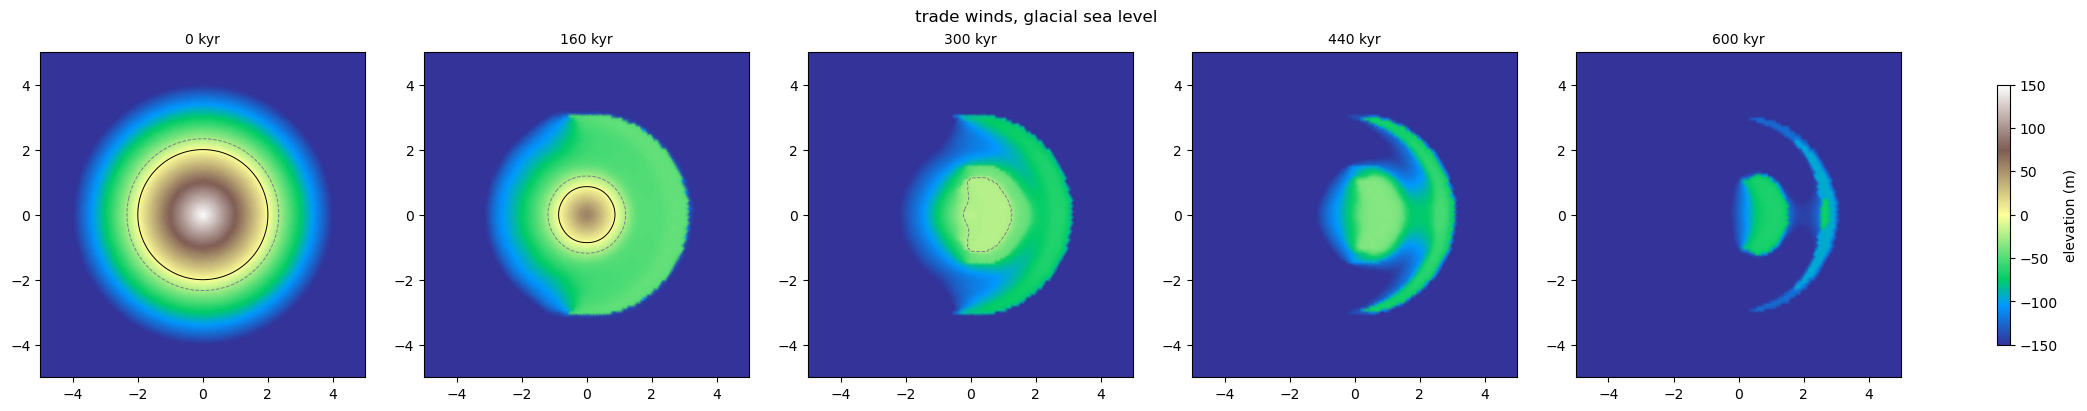

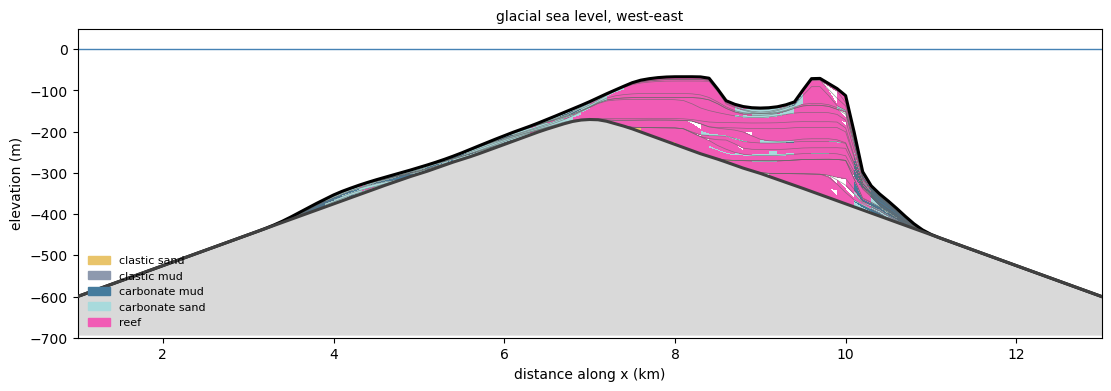

In [6]:
A.evolution('sim_sealevel', n=5, title='trade winds, glacial sea level')
A.section('sim_sealevel', 'x', title='glacial sea level, west-east');